# 홍보 문구 생성 모델 비교 (기능 A)

게임 스크린샷과 요청 사항(톤)을 입력하면 스토어 소개 문구 2문장과 SNS 홍보 문구 1문장을 만드는 기능 A의 모델을 정한다.

- 가이드는 OpenAI API를 제공한다고 했지만 이번 프로젝트에서는 실제로 제공되지 않아, Claude API를 쓴다.
- 후보는 Claude API의 현행 모델 3개(Haiku 5.5, Sonnet 5.5, Opus 5.5)이다. 모델 ID·단가는 Claude 문서 Models overview·Pricing 페이지 기준이다(10/20 확인).
- 비교 지표는 응답 시간, 1회 비용(토큰 사용량 × 문서 단가), 형식 준수율(스토어 2문장 + SNS 1문장), 한국어 비율이다.
- 실험 설정값(표본 수, 톤, 게임 정보, 최대 출력 토큰)은 근거가 없어서, 마지막 "근거 실험" 섹션에서 각각 비교로 근거를 만든다.
- 키는 `.env`의 `ANTHROPIC_API_KEY`에서 읽는다. 노트북에는 키 값을 출력하지 않는다.

## 검토했던 로컬 후보 (측정하지 않음)

10/15에 Hugging Face image-text-to-text 모델 12개(Qwen2.5-VL-7B, Qwen3-VL-8B, gemma-3-12b/4b, InternVL3-8B, MiniCPM-V-4.5, Phi-4-multimodal, Llama-3.2-11B-Vision, SmolVLM2-2.2B, pixtral-12b, kanana-1.5-v-3b, llava-onevision-7b)를 후보로 정리했다. 일정상 로컬 비교는 하지 않고 Claude API 모델끼리만 비교한다.

## 의존성 설치

In [1]:
# 나머지 패키지는 requirements.txt에 고정된 버전을 씀 (-U로 올리지 않음)
%pip install anthropic

Note: you may need to restart the kernel to use updated packages.


## 환경 확인

In [2]:
import os

import anthropic
from dotenv import load_dotenv

load_dotenv('../.env')
print('anthropic', anthropic.__version__)
print('ANTHROPIC_API_KEY 있음' if os.getenv('ANTHROPIC_API_KEY') else 'ANTHROPIC_API_KEY 없음 → ../.env에 추가 필요')

anthropic 2.1.0
ANTHROPIC_API_KEY 있음


## 비교 설정

| 게임 | 입력 이미지 | 폴더 |
|---|---|---|
| 냥기사의 여행 | NAI 생성 이미지 중 screenshot 종류 80장 | `data/raw/nai/lora_gen/*_screenshot.png` |
| 0x72 | 타일·스프라이트 조합 장면 | `data/raw/pixel_0x72/scenes` |
| KayKit | 캐릭터 Blender 렌더 | `data/raw/kaykit/renders` |

게임마다 5장을 무작위(seed 0)로 뽑아 3개 모델에 같은 입력을 넣는다. 15장 × 3모델 = 45회 호출이다. 5장이 충분한지는 "근거 실험 1"에서 확인한다.

설정값의 근거는 다음과 같다.

| 값 | 근거 | 확인 위치 |
|---|---|---|
| `N_PER_GAME = 5` | 없음 | 근거 실험 1 (표본 수) |
| `MAX_TOKENS = 8000` | 사고 토큰 여유. 숫자 자체는 근거 없음 | 근거 실험 2 (최대 출력 토큰) |
| `TONE` | 톤 입력은 가이드 구현 기능 예시의 "문구에 대한 요청 사항(스타일, 톤 등)". 값 자체는 근거 없음 | 근거 실험 3 (톤) |
| `GAMES`의 `info` | 내용은 데이터에서 가져옴(NAI 원본 파일명 "2d side-scrolling adventure, black cat", 0x72 DungeonTileset, KayKit Character Pack Adventures). 넣어야 하는 이유는 근거 없음 | 근거 실험 4 (게임 정보) |
| effort 기본값 | 서비스에서 기본값으로 호출할 때의 시간·비용을 보기 위함 | — |

In [3]:
import random
from pathlib import Path

RAW = Path('../data/raw')
OUT_DIR = Path('../outputs/copy_compare')
OUT_DIR.mkdir(parents=True, exist_ok=True)
RECORDS_CSV = OUT_DIR / 'claude_copy.csv'
JUDGE_CSV = OUT_DIR / 'claude_judge.csv'

# Models overview 페이지의 Claude API ID (10/20 확인)
MODELS = ['claude-haiku-5-5', 'claude-sonnet-5-5', 'claude-opus-5-5']
# Pricing 페이지 기준 USD / 1M 토큰 (10/20 확인). Haiku는 프롬프트 100,000토큰 이하 구간 단가 (이 실험의 입력은 이미지 1장 + 지시문이라 이 구간에 듦)
PRICE = {
    'claude-haiku-5-5':  dict(input=0.10, output=0.50),
    'claude-sonnet-5-5': dict(input=2.0, output=10.0),
    'claude-opus-5-5':   dict(input=4.0, output=20.0),
}
# 사고(thinking) 토큰까지 들어갈 여유. 잘리면 stop_reason이 max_tokens로 기록되고 근거 실험 2에서 확인
MAX_TOKENS = 8000

GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')),
                info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')),
                   info='로우폴리 3D 판타지 어드벤처 게임'),
}
N_PER_GAME = 5
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], N_PER_GAME)]

TONE = '밝고 친근한 톤'
# 근거 실험 3: 톤을 지시대로 바꾸는지 보려고 서로 겹치지 않는 톤 3개를 둠 (첫 번째가 본 비교의 TONE)
TONES = [TONE, '진지하고 웅장한 톤', '유머러스하고 장난스러운 톤']
# 근거 실험 3·4의 채점 모델. 4번은 같은 모델 안에서 정보 유무만 비교하므로 채점 모델의 자기 선호 편향이 양쪽에 똑같이 들어감
JUDGE_MODEL = 'claude-opus-5-5'

SYSTEM = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'
INSTRUCTION = '''{info_line}요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''

print({g: len(d['files']) for g, d in GAMES.items()}, '→', len(SAMPLES), 'images ×', len(MODELS), 'models')

{'nai': 80, 'x72': 520, 'kaykit': 520} → 15 images × 3 models


## 생성 및 측정

- 이미지는 PNG(RGB)로 바꿔 base64로 보낸다. 세 게임 이미지 모두 1024×1024이다(03 EDA "6. 학습 데이터").
- effort는 모델 기본값을 그대로 쓴다.
- 응답 시간은 요청을 보내고 전체 응답을 받을 때까지의 시간이다.
- 호출마다 `claude_copy.csv`에 (모델, 이미지, 톤, 게임 정보 사용 여부)와 함께 바로 저장한다. 다시 실행하면 이미 성공한 조합은 건너뛰고 오류 난 호출만 다시 한다.
- 이 셀은 본 비교 조건(`TONE`, 게임 정보 사용)만 실행한다. 다른 조건은 근거 실험 섹션에서 같은 함수로 실행한다.

In [4]:
import base64
import io
import time

import pandas as pd
from PIL import Image

client = anthropic.Anthropic()
_b64_cache = {}


def image_b64(path):
    if path not in _b64_cache:
        buf = io.BytesIO()
        # NAI PNG의 알파 채널은 투명도가 아니라 메타데이터(03 EDA 6-2)라서 RGB로 변환
        Image.open(path).convert('RGB').save(buf, format='PNG')
        _b64_cache[path] = base64.standard_b64encode(buf.getvalue()).decode()
    return _b64_cache[path]


def image_block(path):
    return {'type': 'image', 'source': {'type': 'base64', 'media_type': 'image/png', 'data': image_b64(path)}}


def call(model, content, system=None, max_tokens=MAX_TOKENS):
    kw = dict(model=model, max_tokens=max_tokens, messages=[{'role': 'user', 'content': content}])
    if system:
        kw['system'] = system
    t0 = time.perf_counter()
    r = client.messages.create(**kw)
    sec = round(time.perf_counter() - t0, 2)
    # 사고 블록은 빼고 텍스트 블록만 씀
    text = ''.join(b.text for b in r.content if b.type == 'text')
    return dict(sec=sec, input_tokens=r.usage.input_tokens, output_tokens=r.usage.output_tokens,
                stop_reason=r.stop_reason, text=text)


def done_keys(csv, cols):
    if not csv.exists():
        return set()
    prev = pd.read_csv(csv, keep_default_na=False, dtype=str)
    return {tuple(r[c] for c in cols) for _, r in prev.iterrows() if r['error'] == ''}


def append(csv, rec):
    pd.DataFrame([rec]).to_csv(csv, mode='a', header=not csv.exists(), index=False, encoding='utf-8')


def generate(tone=TONE, use_info=True, models=MODELS):
    done = done_keys(RECORDS_CSV, ['model', 'file', 'tone', 'use_info'])
    for game, path in SAMPLES:
        info_line = f"게임 정보: {GAMES[game]['info']}\n" if use_info else ''
        prompt = INSTRUCTION.format(info_line=info_line, tone=tone)
        for model in models:
            if (model, path.name, tone, str(use_info)) in done:
                continue
            rec = dict(model=model, game=game, file=path.name, tone=tone, use_info=use_info, sec=None, input_tokens=None,
                       output_tokens=None, stop_reason=None, text='', error='')
            try:
                rec.update(call(model, [image_block(path), {'type': 'text', 'text': prompt}], system=SYSTEM))
            except Exception as e:
                rec['error'] = f'{type(e).__name__}: {e}'[:300]
            append(RECORDS_CSV, rec)
            print(f"{model:18s} {game:6s} {path.name:28s} tone={tone[:6]} info={use_info} {rec['sec']}s "
                  f"in={rec['input_tokens']} out={rec['output_tokens']} {rec['stop_reason']} {rec['error'][:100]}", flush=True)


generate()

claude-haiku-5-5   nai    gen_0729_screenshot.png      tone=밝고 친근한 info=True 2.35s in=1625 out=235 end_turn 
claude-sonnet-5-5  nai    gen_0729_screenshot.png      tone=밝고 친근한 info=True 4.42s in=1625 out=286 end_turn 
claude-opus-5-5    nai    gen_0729_screenshot.png      tone=밝고 친근한 info=True 6.21s in=1625 out=373 end_turn 
claude-haiku-5-5   nai    gen_0733_screenshot.png      tone=밝고 친근한 info=True 2.1s in=1625 out=201 end_turn 
claude-sonnet-5-5  nai    gen_0733_screenshot.png      tone=밝고 친근한 info=True 3.39s in=1625 out=270 end_turn 
claude-opus-5-5    nai    gen_0733_screenshot.png      tone=밝고 친근한 info=True 5.04s in=1625 out=235 end_turn 
claude-haiku-5-5   nai    gen_0685_screenshot.png      tone=밝고 친근한 info=True 3.79s in=1625 out=253 end_turn 
claude-sonnet-5-5  nai    gen_0685_screenshot.png      tone=밝고 친근한 info=True 2.92s in=1625 out=283 end_turn 
claude-opus-5-5    nai    gen_0685_screenshot.png      tone=밝고 친근한 info=True 5.31s in=1625 out=293 end_turn 
claude-haiku-5-5   n

## 지표 계산

- **형식 준수**: 응답이 JSON으로 읽히고, `store`가 2문장, `sns`가 1문장이면 준수로 본다. 문장 수는 `.`, `!`, `?`, `…` 뒤에서 나눠 세고, 글자가 없는 조각(끝의 이모지 등)은 세지 않는다.
- **한국어 비율**: 글자(한글·영문·한자) 중 한글의 비율이다. 숫자·기호·이모지는 세지 않는다.
- **1회 비용**: 입력 토큰 × 입력 단가 + 출력 토큰 × 출력 단가. 출력 토큰은 API `usage.output_tokens` 값을 그대로 쓴다.
- 표는 본 비교 조건(`TONE`, 게임 정보 사용)만 집계한다.

In [5]:
import json
import re

KEYS = ['model', 'file', 'tone', 'use_info']


def parse(text):
    m = re.search(r'\{.*\}', text, re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    if not isinstance(d, dict) or not isinstance(d.get('store'), list) or not isinstance(d.get('sns'), str):
        return None
    return d


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def korean_ratio(s):
    hangul = len(re.findall(r'[가-힣]', s))
    letters = hangul + len(re.findall(r'[A-Za-z一-鿿]', s))
    return hangul / letters if letters else 0.0


def load_scored():
    raw = pd.read_csv(RECORDS_CSV, keep_default_na=False, dtype=str)
    ok = raw[raw.error == ''].drop_duplicates(KEYS, keep='last').copy()
    ok['use_info'] = ok.use_info == 'True'
    for c in ['sec', 'input_tokens', 'output_tokens']:
        ok[c] = pd.to_numeric(ok[c])
    parsed = ok.text.map(parse)
    ok['json_ok'] = parsed.notna()
    ok['store_n'] = [sum(n_sentences(x) for x in d['store']) if d else None for d in parsed]
    ok['sns_n'] = [n_sentences(d['sns']) if d else None for d in parsed]
    ok['format_ok'] = ok.json_ok & (ok.store_n == 2) & (ok.sns_n == 1)
    ok['store'] = [' '.join(map(str, d['store'])) if d else '' for d in parsed]
    ok['sns'] = [d['sns'] if d else '' for d in parsed]
    ok['ko_ratio'] = [korean_ratio(a + ' ' + b) if j else None for a, b, j in zip(ok.store, ok.sns, ok.json_ok)]
    ok['cost_usd'] = [i / 1e6 * PRICE[m]['input'] + o / 1e6 * PRICE[m]['output']
                      for m, i, o in zip(ok.model, ok.input_tokens, ok.output_tokens)]
    ok_keys = set(zip(*[ok[k].astype(str) for k in KEYS]))
    unresolved = raw[(raw.error != '') & pd.Series([k not in ok_keys for k in zip(*[raw[k] for k in KEYS])], index=raw.index)]
    return raw, ok, unresolved


raw, allrec, unresolved = load_scored()
allrec.to_csv(OUT_DIR / 'claude_copy_scored.csv', index=False, encoding='utf-8-sig')
rec = allrec[(allrec.tone == TONE) & allrec.use_info].copy()

summary = rec.groupby('model', sort=False).agg(
    calls=('file', 'size'), sec_mean=('sec', 'mean'), sec_std=('sec', 'std'), sec_max=('sec', 'max'),
    out_tokens=('output_tokens', 'mean'), cost_usd=('cost_usd', 'mean'),
    json_ok=('json_ok', 'mean'), format_ok=('format_ok', 'mean'), ko_ratio=('ko_ratio', 'mean'),
    max_tokens_cut=('stop_reason', lambda s: (s == 'max_tokens').sum())).reindex(MODELS)
summary['cost_usd_per_100_calls'] = summary.cost_usd * 100
summary.to_csv(OUT_DIR / 'claude_copy_summary.csv', encoding='utf-8-sig')
print('오류 기록', (raw.error != '').sum(), '건 / 재실행 후에도 남은 오류', len(unresolved), '건')
display(unresolved[KEYS + ['error']])
display(summary.round(4))
display(rec.groupby(['model', 'game'], sort=False)[['sec', 'cost_usd', 'format_ok', 'ko_ratio']].mean().round(4))

오류 기록 0 건 / 재실행 후에도 남은 오류 0 건


,model,file,tone,use_info,error


,calls,sec_mean,sec_std,sec_max,out_tokens,cost_usd,json_ok,format_ok,ko_ratio,max_tokens_cut,cost_usd_per_100_calls
model,,,,,,,,,,,
claude-haiku-5-5,15,3.5600,1.3209,6.39,316.2667,0.0003,1.0,0.6667,0.9960,0,0.0319
claude-sonnet-5-5,15,3.1547,0.4697,4.42,245.2667,0.0057,1.0,0.4667,0.9968,0,0.5668
claude-opus-5-5,15,5.7293,0.7674,7.81,319.6000,0.0128,1.0,0.8000,0.9991,0,1.2823


,,sec,cost_usd,format_ok,ko_ratio
model,game,,,,
claude-haiku-5-5,nai,2.962,0.0003,0.6,0.9933
claude-sonnet-5-5,nai,3.504,0.0059,0.4,0.9919
claude-opus-5-5,nai,5.598,0.0124,0.8,0.9972
claude-haiku-5-5,x72,4.358,0.0003,0.6,0.9981
claude-sonnet-5-5,x72,2.990,0.0056,0.6,1.0000
claude-opus-5-5,x72,5.536,0.0126,1.0,1.0000
claude-haiku-5-5,kaykit,3.360,0.0003,0.8,0.9966
claude-sonnet-5-5,kaykit,2.970,0.0055,0.4,0.9986
claude-opus-5-5,kaykit,6.054,0.0134,0.6,1.0000


## 시각화

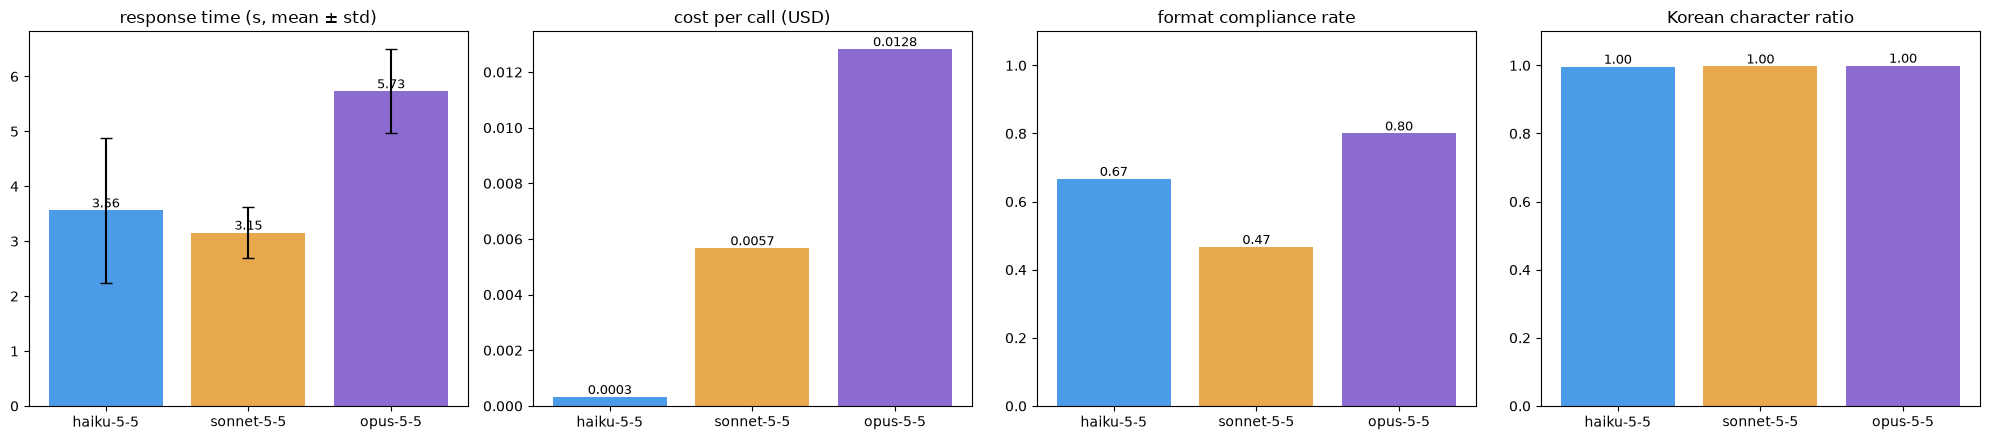

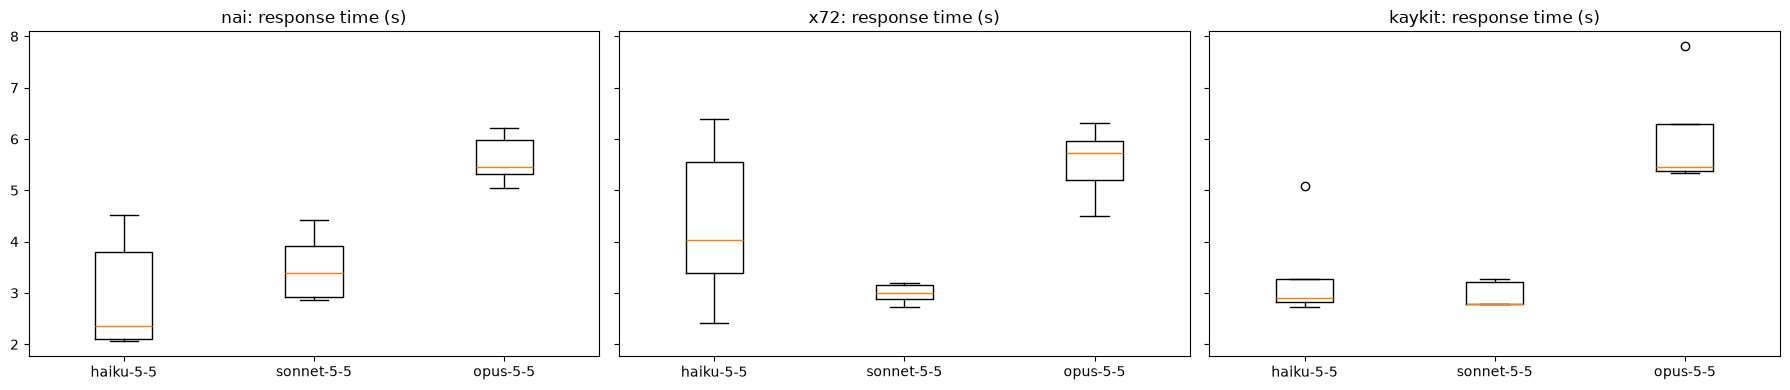

In [6]:
import matplotlib.pyplot as plt
import numpy as np

short = {m: m.replace('claude-', '') for m in MODELS}
COLORS = ['#4C9BE8', '#E8A84C', '#8C6BD1']
x = np.arange(len(MODELS))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
panels = [
    ('sec_mean', 'response time (s, mean ± std)', 'sec_std'),
    ('cost_usd', 'cost per call (USD)', None),
    ('format_ok', 'format compliance rate', None),
    ('ko_ratio', 'Korean character ratio', None),
]
for ax, (col, title, err) in zip(axes, panels):
    v = summary[col].values
    ax.bar(x, v, yerr=summary[err].values if err else None, capsize=4, color=COLORS)
    for i, val in enumerate(v):
        ax.text(i, val, f'{val:.4f}' if col == 'cost_usd' else f'{val:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x, [short[m] for m in MODELS])
    ax.set_title(title)
    if col in ('format_ok', 'ko_ratio'):
        ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig(OUT_DIR / 'claude_copy_bars.png', dpi=90)
plt.show()

# 게임별 응답 시간 분포
games = list(GAMES)
fig, axes = plt.subplots(1, len(games), figsize=(6 * len(games), 4), sharey=True)
for ax, g in zip(axes, games):
    ax.boxplot([rec[(rec.model == m) & (rec.game == g)].sec.values for m in MODELS])
    ax.set_xticks(x + 1, [short[m] for m in MODELS])
    ax.set_title(f'{g}: response time (s)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'claude_copy_sec_by_game.png', dpi=90)
plt.show()

## 문구 비교

게임마다 첫 번째 입력 이미지에 대해 세 모델의 문구를 나란히 본다.

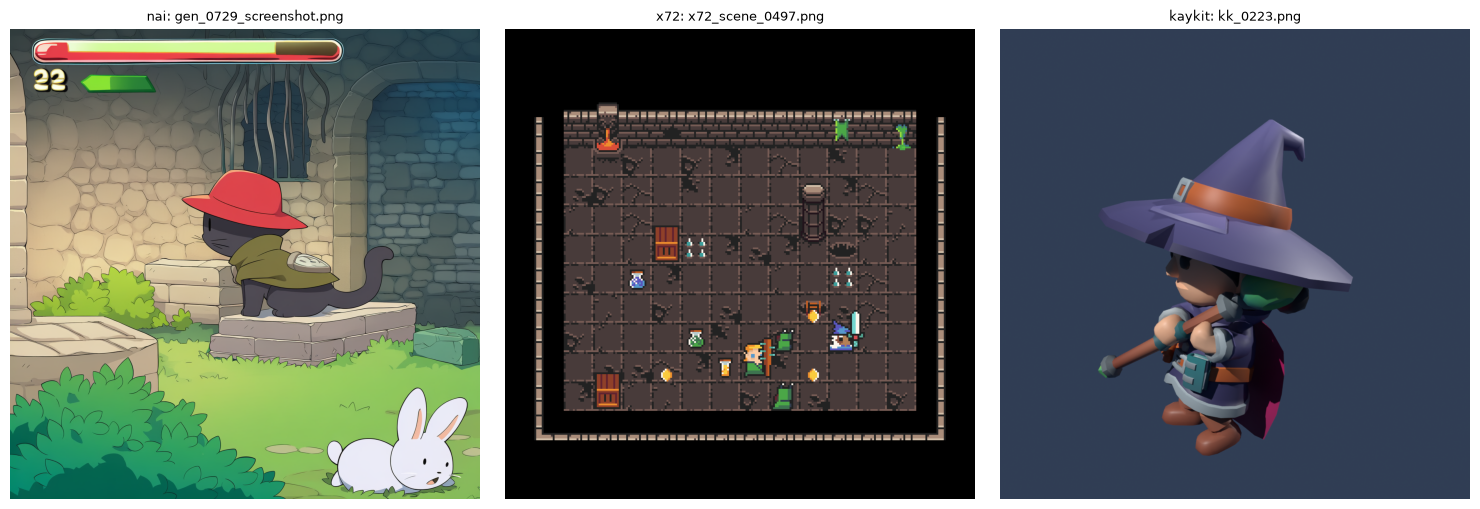

,game,file,model,store,sns,format_ok,sec
30,kaykit,kk_0223.png,claude-haiku-5-5,"작은 마법사가 모자를 꾹 눌러쓰고 떠나는, 로우폴리 3D 판타지 어드벤처의 세계에 여러분을 초대합니다. 귀여운 캐릭터와 알록달록한 마법의 여정이 기다리는 이곳에서, 오늘도 즐거운 모험을 시작해 보세요!","뾰족한 모자 쓰고 지팡이 든 우리 마법사와 함께, 반짝이는 로우폴리 판타지 모험 떠날 준비 되셨나요? ✨",True,2.83
31,kaykit,kk_0223.png,claude-sonnet-5-5,"커다란 마법사 모자를 쓴 꼬마 마법사와 함께 알록달록한 로우폴리 판타지 세계로 모험을 떠나 보세요! 지팡이 하나 둘러메고 마법 가득한 길을 걷다 보면, 아기자기한 풍경 속에서 뜻밖의 즐거움과 따뜻한 이야기가 기다리고 있어요.","🧙‍♂️ 모자는 크게, 모험은 더 크게! 귀여운 꼬마 마법사와 함께 떠나는 로우폴리 판타지 어드벤처에 놀러 오세요 ✨",False,3.21
32,kaykit,kk_0223.png,claude-opus-5-5,커다란 보라색 모자를 눌러쓴 꼬마 마법사와 함께 알록달록한 로우폴리 판타지 세계로 신나는 모험을 떠나보세요! 든든한 지팡이와 작은 가방 하나만 챙기면 어디서든 새로운 친구와 놀라운 비밀을 만날 수 있어요.,"모자는 크게, 용기는 더 크게! 귀여운 꼬마 마법사의 두근두근 판타지 모험이 지금 시작됩니다 ✨",False,5.33
0,nai,gen_0729_screenshot.png,claude-haiku-5-5,"빨간 모자를 쓴 검은 고양이 기사가 돌담 마을과 초록 들판을 누비는 2D 횡스크롤 모험, 냥기사의 여행이 시작됩니다! 귀여운 토끼 친구들과 마주치며 용감하게 길을 떠나는 고양이 기사와 함께, 따뜻하고 아기자기한 세계를 탐험해 보세요.","빨간 모자 쓴 검은 고양이 기사가 떠나는 모험, 냥기사의 여행과 함께 오늘도 귀여운 모험을 떠나볼까요? 🐾⚔️",True,2.35
1,nai,gen_0729_screenshot.png,claude-sonnet-5-5,"빨간 모자를 눌러쓴 검은 고양이 기사와 함께 이끼 낀 오래된 성터를 누비며 숨겨진 비밀을 찾아 떠나는 2D 횡스크롤 어드벤처 <냥기사의 여행>입니다. 손그림 같은 따뜻한 풍경 속에서 귀여운 토끼 친구들을 만나고 작은 모험을 하나씩 이겨 내며, 포근하고 즐거운 여정을 느껴 보세요.",빨간 모자 쓴 냥기사와 함께 폭신폭신 모험을 떠나요 🐱🎩 <냥기사의 여행>에서 귀여운 친구들이 기다리고 있어요! #냥기사의여행 #인디게임,False,4.42
2,nai,gen_0729_screenshot.png,claude-opus-5-5,빨간 모자와 망토를 두른 작은 검은 고양이 기사가 이끼 낀 고성의 폐허 속으로 씩씩하게 모험을 떠납니다! 풀숲에 숨은 새하얀 토끼 친구와 오래된 돌벽 너머의 비밀을 찾아 따뜻하고 귀여운 2D 횡스크롤 여행을 함께 즐겨보세요.,"빨간 모자 냥기사가 고성 폐허에서 새하얀 토끼를 만났어요, 이 귀여운 모험에 함께 떠나볼까요? 🐾",True,6.21
15,x72,x72_scene_0497.png,claude-haiku-5-5,"어둡고 축축한 던전 속에서도 반짝이는 금화와 물약, 그리고 든든한 검 한 자루가 여러분의 모험을 응원해요! 초록 몬스터들이 기다리는 낡은 석조 던전을 함께 누비며 보물상자를 열어보세요, 어떤 비밀이 숨어 있을까요?","던전 속 보물과 물약이 여러분을 기다리고 있어요, 지금 바로 떠나는 신나는 픽셀 모험에 함께해요! ⚔️✨",True,5.56
16,x72,x72_scene_0497.png,claude-sonnet-5-5,"함정과 슬라임이 가득한 아기자기한 픽셀 던전 속에서, 반짝이는 금화와 알록달록 포션을 모으며 나만의 모험을 시작해 보세요! 귀여운 도트 그래픽과 쏠쏠한 보물 상자의 재미가 가득해서, 던전 탐험이 처음인 분들도 누구나 즐겁게 빠져들 수 있어요.","초록 슬라임과 눈치싸움하고 반짝이는 금화를 줍는 귀여운 픽셀 던전 탐험, 지금 함께 떠나요! ✨🗡️",True,2.73
17,x72,x72_scene_0497.png,claude-opus-5-5,알록달록 포션과 반짝이는 금화가 가득한 아기자기한 픽셀 던전에서 귀여운 초록 슬라임들과 한바탕 모험을 즐겨보세요! 곳곳에 숨은 가시 함정을 피하고 보물상자를 열며 나만의 탐험 이야기를 만들어가는 재미가 기다리고 있어요.,"포션 한 병, 금화 한 닢, 그리고 슬라임 친구들까지, 오늘은 귀여운 픽셀 던전으로 모험 떠나볼까요? ✨",True,5.72


In [7]:
first = {g: next(p for gg, p in SAMPLES if gg == g) for g in GAMES}
fig, axes = plt.subplots(1, len(first), figsize=(5 * len(first), 5))
for ax, (g, p) in zip(axes, first.items()):
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(f'{g}: {p.name}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

pd.set_option('display.max_colwidth', None)
order = {m: i for i, m in enumerate(MODELS)}
cmp = rec[rec.file.isin([p.name for p in first.values()])][['game', 'file', 'model', 'store', 'sns', 'format_ok', 'sec']]
display(cmp.assign(_o=cmp.model.map(order)).sort_values(['game', '_o']).drop(columns='_o'))

## 근거 실험

설정값 4개의 근거를 비교로 만든다.

| 번호 | 대상 | 추가 호출 | 판단 기준 |
|---|---|---|---|
| 1 | `N_PER_GAME` | 없음 (본 비교 결과 재사용) | 모델 간 차이의 95% 부트스트랩 신뢰구간 |
| 2 | `MAX_TOKENS` | 없음 (전체 생성 기록 재사용) | 잘린 응답 수, 최대 출력 토큰 |
| 3 | `TONE` | 생성 90회 + 채점 135회 | 채점 모델이 문구만 보고 지시한 톤을 맞히는 비율 |
| 4 | `GAMES`의 `info` | 생성 45회 + 채점 90회 | 이미지와 문구의 적합도 점수(1~5), 정보 있음 − 없음 |

추가 호출 전에 본 비교의 1회 비용으로 예상 비용을 먼저 계산한다.

In [8]:
gen_cost = summary.cost_usd.sum()
judge_cost = summary.loc[JUDGE_MODEL, 'cost_usd']
est = {
    '3 톤 생성 (톤 2개 추가)': gen_cost * len(SAMPLES) * (len(TONES) - 1),
    '3 톤 채점': judge_cost * len(SAMPLES) * len(MODELS) * len(TONES),
    '4 정보 없음 생성': gen_cost * len(SAMPLES),
    '4 적합도 채점': judge_cost * len(SAMPLES) * len(MODELS) * 2,
}
# 채점은 문구가 짧아 생성보다 출력 토큰이 적을 것이므로 본 비교 1회 비용을 상한으로 씀
display(pd.Series(est, name='USD 상한 추정').round(3))
print('합계 상한 추정 USD', round(sum(est.values()), 3))

3 톤 생성 (톤 2개 추가)    0.564
3 톤 채점              1.731
4 정보 없음 생성          0.282
4 적합도 채점            1.154
Name: USD 상한 추정, dtype: float64

합계 상한 추정 USD 3.732


### 근거 실험 1. 표본 수 (`N_PER_GAME`)

같은 이미지에 대한 두 모델의 지표 차이(대응 표본)를 이미지 단위로 2,000번 재표집해 95% 신뢰구간을 낸다.

- 신뢰구간이 0을 포함하지 않으면, 지금 표본 수로 두 모델의 차이가 구분된다.
- 0을 포함하면, 관측된 차이를 구분하는 데 필요한 장수를 `현재 장수 × (반폭 / |차이|)²`로 어림한다. 신뢰구간 반폭이 표본 수의 제곱근에 반비례한다는 가정을 쓴다.

,metric,pair,n,diff,ci_low,ci_high,separated,n_needed
0,sec,haiku-5-5 − sonnet-5-5,15,0.4053,-0.3447,1.2100,False,56.0
1,sec,haiku-5-5 − opus-5-5,15,-2.1693,-2.7174,-1.5513,True,NaN
2,sec,sonnet-5-5 − opus-5-5,15,-2.5747,-3.0874,-2.1693,True,NaN
3,cost_usd,haiku-5-5 − sonnet-5-5,15,-0.0053,-0.0055,-0.0052,True,NaN
4,cost_usd,haiku-5-5 − opus-5-5,15,-0.0125,-0.0134,-0.0117,True,NaN
5,cost_usd,sonnet-5-5 − opus-5-5,15,-0.0072,-0.0081,-0.0064,True,NaN
6,format_ok,haiku-5-5 − sonnet-5-5,15,0.2000,-0.1333,0.5333,False,42.0
7,format_ok,haiku-5-5 − opus-5-5,15,-0.1333,-0.4667,0.2000,False,94.0
8,format_ok,sonnet-5-5 − opus-5-5,15,-0.3333,-0.6000,0.0000,False,13.0
9,ko_ratio,haiku-5-5 − sonnet-5-5,15,-0.0008,-0.0028,0.0012,False,95.0


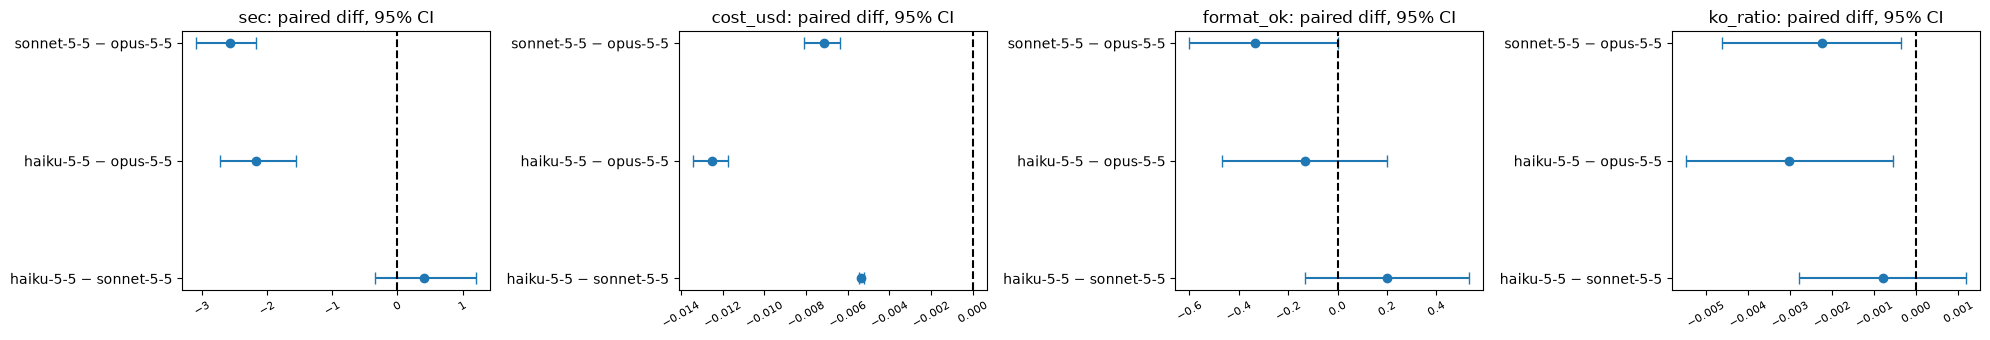

In [9]:
B = 2000
METRICS = ['sec', 'cost_usd', 'format_ok', 'ko_ratio']
boot_rng = np.random.default_rng(0)
rows = []
for metric in METRICS:
    pv = rec.pivot_table(index='file', columns='model', values=metric, aggfunc='first').astype(float)
    for i, a in enumerate(MODELS):
        for b in MODELS[i + 1:]:
            d = (pv[a] - pv[b]).dropna().values
            if len(d) < 2:
                continue
            means = d[boot_rng.integers(0, len(d), (B, len(d)))].mean(1)
            lo, hi = np.percentile(means, [2.5, 97.5])
            half = (hi - lo) / 2
            diff = d.mean()
            separated = lo > 0 or hi < 0
            need = None if separated or diff == 0 else int(np.ceil(len(d) * (half / abs(diff)) ** 2))
            rows.append(dict(metric=metric, pair=f'{short[a]} − {short[b]}', n=len(d), diff=diff, ci_low=lo, ci_high=hi,
                             separated=separated, n_needed=need))
n_check = pd.DataFrame(rows)
n_check.to_csv(OUT_DIR / 'evidence1_sample_size.csv', index=False, encoding='utf-8-sig')
display(n_check.round(4))

fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 3.5))
for ax, metric in zip(axes, METRICS):
    s = n_check[n_check.metric == metric].reset_index(drop=True)
    ax.errorbar(s['diff'], np.arange(len(s)), xerr=[s['diff'] - s.ci_low, s.ci_high - s['diff']], fmt='o', capsize=4)
    ax.axvline(0, color='black', linestyle='--')
    ax.set_yticks(np.arange(len(s)), s.pair)
    ax.set_title(f'{metric}: paired diff, 95% CI')
    ax.tick_params(axis='x', labelsize=8, rotation=30)
plt.tight_layout()
plt.savefig(OUT_DIR / 'evidence1_sample_size.png', dpi=90)
plt.show()

### 근거 실험 2. 최대 출력 토큰 (`MAX_TOKENS`)

지금까지의 모든 생성 기록에서 출력 토큰 분포와 `max_tokens`로 잘린 응답 수를 본다. 잘린 응답이 0건이고 최대값이 `MAX_TOKENS`보다 충분히 작으면 8000은 부족하지 않다는 근거가 된다.

,calls,out_mean,out_max,cut,max_ratio
model,,,,,
claude-haiku-5-5,15,316.267,645,0,0.081
claude-sonnet-5-5,15,245.267,286,0,0.036
claude-opus-5-5,15,319.600,578,0,0.072


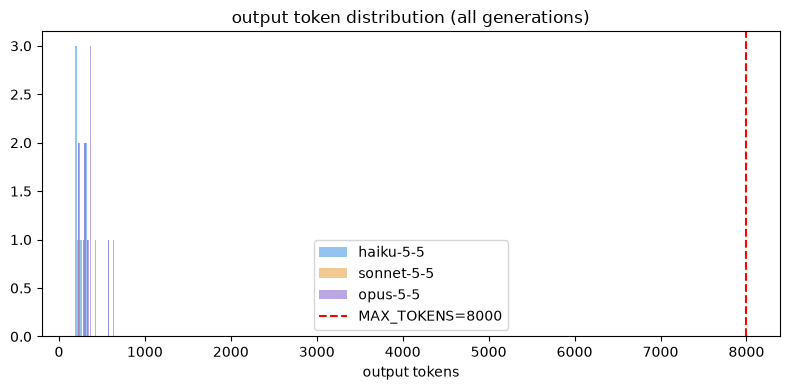

In [10]:
raw, allrec, unresolved = load_scored()
tok = allrec.groupby('model', sort=False).agg(calls=('file', 'size'), out_mean=('output_tokens', 'mean'),
                                              out_max=('output_tokens', 'max'),
                                              cut=('stop_reason', lambda s: (s == 'max_tokens').sum())).reindex(MODELS)
tok['max_ratio'] = tok.out_max / MAX_TOKENS
display(tok.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for m, c in zip(MODELS, COLORS):
    ax.hist(allrec[allrec.model == m].output_tokens, bins=30, alpha=0.6, label=short[m], color=c)
ax.axvline(MAX_TOKENS, color='red', linestyle='--', label=f'MAX_TOKENS={MAX_TOKENS}')
ax.set_xlabel('output tokens')
ax.set_title('output token distribution (all generations)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'evidence2_max_tokens.png', dpi=90)
plt.show()

### 근거 실험 3. 톤 (`TONE`)

같은 이미지·모델로 톤 3개(`TONES`)의 문구를 만들고, 채점 모델이 문구만 보고 셋 중 어느 톤인지 고르게 한다. 보기 순서는 문구마다 무작위로 섞는다.

- 맞힌 비율이 우연 수준(1/3)보다 높으면, 톤 입력이 실제로 문구를 바꾼다는 근거가 된다.
- 기본값을 무엇으로 둘지는 이 실험으로 정해지지 않는다. 톤별 형식 준수율·한국어 비율을 함께 보고 기본값 판단 자료로 쓴다.

claude-haiku-5-5   nai    gen_0729_screenshot.png      tone=진지하고 웅 info=True 4.5s in=1627 out=367 end_turn 
claude-sonnet-5-5  nai    gen_0729_screenshot.png      tone=진지하고 웅 info=True 3.77s in=1627 out=255 end_turn 
claude-opus-5-5    nai    gen_0729_screenshot.png      tone=진지하고 웅 info=True 7.06s in=1627 out=334 end_turn 
claude-haiku-5-5   nai    gen_0733_screenshot.png      tone=진지하고 웅 info=True 4.35s in=1627 out=597 end_turn 
claude-sonnet-5-5  nai    gen_0733_screenshot.png      tone=진지하고 웅 info=True 2.77s in=1627 out=253 end_turn 
claude-opus-5-5    nai    gen_0733_screenshot.png      tone=진지하고 웅 info=True 6.08s in=1627 out=361 end_turn 
claude-haiku-5-5   nai    gen_0685_screenshot.png      tone=진지하고 웅 info=True 7.89s in=1627 out=843 end_turn 
claude-sonnet-5-5  nai    gen_0685_screenshot.png      tone=진지하고 웅 info=True 3.19s in=1627 out=225 end_turn 
claude-opus-5-5    nai    gen_0685_screenshot.png      tone=진지하고 웅 info=True 7.97s in=1627 out=610 end_turn 
claude-haiku-5-5   n

,tone_acc,n
model,,
claude-haiku-5-5,1.0,45
claude-sonnet-5-5,1.0,45
claude-opus-5-5,1.0,45


format_ok  ko_ratio     sec  cost_usd
tone           model                                                   
밝고 친근한 톤       claude-haiku-5-5      0.6667    0.9960  3.5600    0.0003
               claude-sonnet-5-5     0.4667    0.9968  3.1547    0.0057
               claude-opus-5-5       0.8000    0.9991  5.7293    0.0128
진지하고 웅장한 톤     claude-haiku-5-5      0.9333    0.9980  3.8327    0.0004
               claude-sonnet-5-5     0.9333    0.9965  3.1800    0.0055
               claude-opus-5-5       1.0000    0.9996  6.6607    0.0140
유머러스하고 장난스러운 톤 claude-haiku-5-5      0.6667    0.9984  4.7273    0.0005
               claude-sonnet-5-5     0.3333    0.9980  4.3860    0.0061
               claude-opus-5-5       0.8667    0.9990  8.7567    0.0173

tone labels: {'밝고 친근한 톤': 'tone1', '진지하고 웅장한 톤': 'tone2', '유머러스하고 장난스러운 톤': 'tone3'}


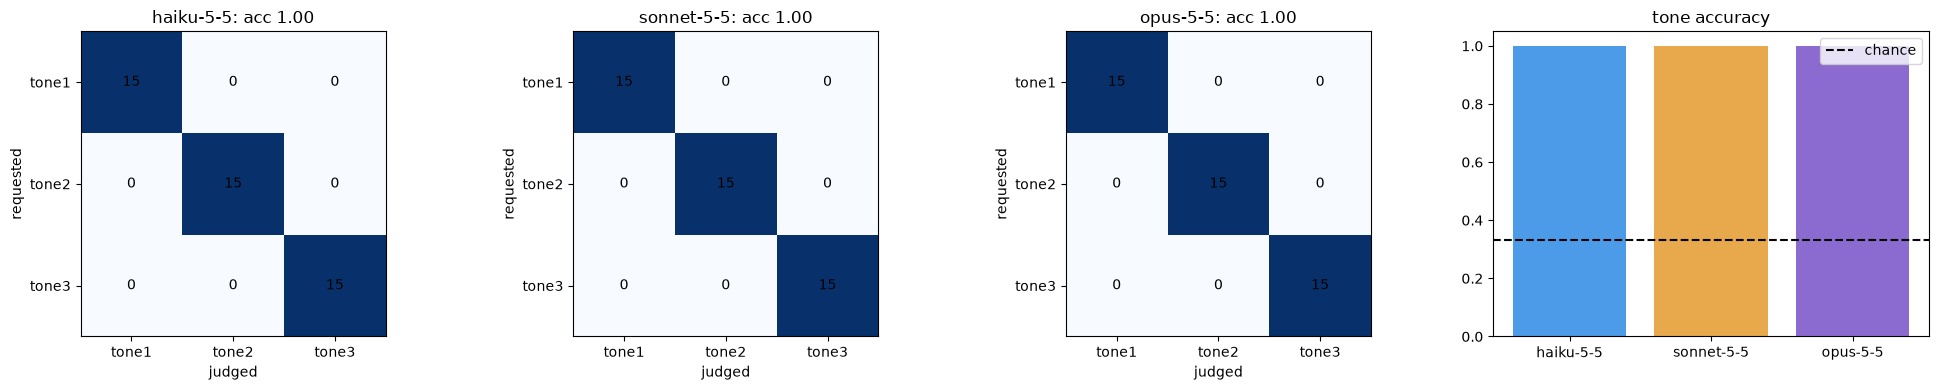

In [11]:
for tone in TONES[1:]:
    generate(tone=tone)

TONE_JUDGE = '''다음은 게임 홍보 문구다.

스토어: {store}
SNS: {sns}

이 문구의 톤으로 가장 가까운 것을 보기에서 하나만 골라라.
{options}
아래 JSON 형식으로만 답해라. {{"choice": "A"}}'''

raw, allrec, unresolved = load_scored()
tone_rec = allrec[allrec.use_info & allrec.tone.isin(TONES) & allrec.json_ok]
jdone = done_keys(JUDGE_CSV, ['task', 'model', 'file', 'tone', 'use_info'])
for _, r in tone_rec.iterrows():
    key = ('tone', r.model, r.file, r.tone, str(r.use_info))
    if key in jdone:
        continue
    opts = TONES[:]
    random.Random(f'{r.model}{r.file}{r.tone}').shuffle(opts)
    letters = 'ABC'
    prompt = TONE_JUDGE.format(store=r.store, sns=r.sns, options='\n'.join(f'{l}. {t}' for l, t in zip(letters, opts)))
    jr = dict(task='tone', model=r.model, file=r.file, tone=r.tone, use_info=r.use_info, answer='', score=None, error='')
    try:
        out = call(JUDGE_MODEL, [{'type': 'text', 'text': prompt}])
        m = re.search(r'"choice"\s*:\s*"([ABC])"', out['text'])
        jr['answer'] = opts[letters.index(m.group(1))] if m else ''
    except Exception as e:
        jr['error'] = f'{type(e).__name__}: {e}'[:300]
    append(JUDGE_CSV, jr)

jd = pd.read_csv(JUDGE_CSV, keep_default_na=False, dtype=str)
tj = jd[(jd.task == 'tone') & (jd.error == '')].drop_duplicates(['model', 'file', 'tone'], keep='last').copy()
tj['correct'] = tj.answer == tj.tone
acc = tj.groupby('model', sort=False).correct.agg(['mean', 'size']).reindex(MODELS).rename(columns={'mean': 'tone_acc', 'size': 'n'})
display(acc.round(3))
tone_tbl = allrec[allrec.use_info & allrec.tone.isin(TONES)].groupby(['tone', 'model'], sort=False)[
    ['format_ok', 'ko_ratio', 'sec', 'cost_usd']].mean()
display(tone_tbl.round(4))
tj.to_csv(OUT_DIR / 'evidence3_tone_judge.csv', index=False, encoding='utf-8-sig')

TONE_EN = {t: f'tone{i + 1}' for i, t in enumerate(TONES)}
print('tone labels:', TONE_EN)
fig, axes = plt.subplots(1, len(MODELS) + 1, figsize=(5 * (len(MODELS) + 1), 4))
for ax, m in zip(axes, MODELS):
    s = tj[tj.model == m]
    mat = pd.crosstab(s.tone.map(TONE_EN), s.answer.map(TONE_EN).fillna('none')).reindex(
        index=list(TONE_EN.values()), columns=list(TONE_EN.values()), fill_value=0)
    ax.imshow(mat.values, cmap='Blues')
    for (i, j), v in np.ndenumerate(mat.values):
        ax.text(j, i, v, ha='center', va='center')
    ax.set_xticks(range(len(TONES)), mat.columns)
    ax.set_yticks(range(len(TONES)), mat.index)
    ax.set_xlabel('judged')
    ax.set_ylabel('requested')
    ax.set_title(f'{short[m]}: acc {acc.loc[m, "tone_acc"]:.2f}')
axes[-1].bar(x, acc.tone_acc.values, color=COLORS)
axes[-1].axhline(1 / len(TONES), color='black', linestyle='--', label='chance')
axes[-1].set_xticks(x, [short[m] for m in MODELS])
axes[-1].set_ylim(0, 1.05)
axes[-1].set_title('tone accuracy')
axes[-1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'evidence3_tone.png', dpi=90)
plt.show()

### 근거 실험 4. 게임 정보 (`GAMES`의 `info`)

같은 이미지·모델·톤으로 게임 정보를 빼고 문구를 만든다. 채점 모델에게 이미지와 문구만 주고(정보 유무는 알려주지 않음) 이미지와 문구가 얼마나 맞는지 1~5점을 매기게 한다.

- 같은 이미지에서 (정보 있음 − 정보 없음) 점수 차이의 95% 부트스트랩 신뢰구간이 0보다 크면, 게임 정보를 넣는 근거가 된다.
- 냥기사 문구에 게임 이름("냥기사")이 들어간 비율도 함께 본다. 이 이름은 이미지만으로는 알 수 없다.

claude-haiku-5-5   nai    gen_0729_screenshot.png      tone=밝고 친근한 info=False 3.46s in=1572 out=265 end_turn 
claude-sonnet-5-5  nai    gen_0729_screenshot.png      tone=밝고 친근한 info=False 3.63s in=1572 out=248 end_turn 
claude-opus-5-5    nai    gen_0729_screenshot.png      tone=밝고 친근한 info=False 6.75s in=1572 out=362 end_turn 
claude-haiku-5-5   nai    gen_0733_screenshot.png      tone=밝고 친근한 info=False 4.52s in=1572 out=566 end_turn 
claude-sonnet-5-5  nai    gen_0733_screenshot.png      tone=밝고 친근한 info=False 4.16s in=1572 out=255 end_turn 
claude-opus-5-5    nai    gen_0733_screenshot.png      tone=밝고 친근한 info=False 6.57s in=1572 out=376 end_turn 
claude-haiku-5-5   nai    gen_0685_screenshot.png      tone=밝고 친근한 info=False 3.08s in=1572 out=338 end_turn 
claude-sonnet-5-5  nai    gen_0685_screenshot.png      tone=밝고 친근한 info=False 3.13s in=1572 out=224 end_turn 
claude-opus-5-5    nai    gen_0685_screenshot.png      tone=밝고 친근한 info=False 5.23s in=1572 out=285 end_turn 
claude-hai

,n,with_info,without_info,diff,ci_low,ci_high
model,,,,,,
claude-haiku-5-5,15,4.333,4.400,-0.067,-0.467,0.333
claude-sonnet-5-5,15,4.333,4.733,-0.400,-0.668,-0.067
claude-opus-5-5,15,4.667,4.933,-0.267,-0.533,-0.067


use_info,True,False
model,,
claude-haiku-5-5,1.0,0.0
claude-sonnet-5-5,1.0,0.0
claude-opus-5-5,1.0,0.0


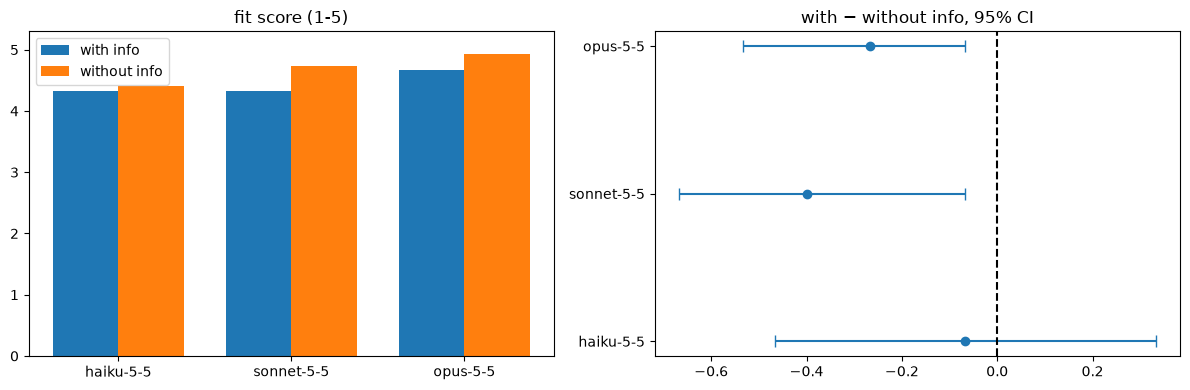

In [12]:
generate(use_info=False)

FIT_JUDGE = '''이 게임 스크린샷과 아래 홍보 문구를 보고, 문구가 스크린샷의 게임(장르, 분위기, 등장 요소)과 얼마나 맞는지 1~5점으로 매겨라.
1 = 전혀 맞지 않음, 3 = 일부만 맞음, 5 = 매우 잘 맞음

스토어: {store}
SNS: {sns}

아래 JSON 형식으로만 답해라. {{"score": 3}}'''

raw, allrec, unresolved = load_scored()
path_of = {p.name: p for _, p in SAMPLES}
fit_rec = allrec[(allrec.tone == TONE) & allrec.json_ok]
jdone = done_keys(JUDGE_CSV, ['task', 'model', 'file', 'tone', 'use_info'])
for _, r in fit_rec.iterrows():
    key = ('fit', r.model, r.file, r.tone, str(r.use_info))
    if key in jdone:
        continue
    jr = dict(task='fit', model=r.model, file=r.file, tone=r.tone, use_info=r.use_info, answer='', score=None, error='')
    try:
        out = call(JUDGE_MODEL, [image_block(path_of[r.file]), {'type': 'text', 'text': FIT_JUDGE.format(store=r.store, sns=r.sns)}])
        m = re.search(r'"score"\s*:\s*([1-5])', out['text'])
        jr['score'] = int(m.group(1)) if m else None
    except Exception as e:
        jr['error'] = f'{type(e).__name__}: {e}'[:300]
    append(JUDGE_CSV, jr)

jd = pd.read_csv(JUDGE_CSV, keep_default_na=False, dtype=str)
fj = jd[(jd.task == 'fit') & (jd.error == '') & (jd.score != '')].drop_duplicates(['model', 'file', 'use_info'], keep='last').copy()
fj['score'] = pd.to_numeric(fj.score)
fj['use_info'] = fj.use_info == 'True'
rows = []
for m in MODELS:
    pv = fj[fj.model == m].pivot_table(index='file', columns='use_info', values='score', aggfunc='first')
    if True not in pv or False not in pv:
        continue
    d = (pv[True] - pv[False]).dropna().values
    means = d[boot_rng.integers(0, len(d), (B, len(d)))].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    rows.append(dict(model=m, n=len(d), with_info=pv[True].mean(), without_info=pv[False].mean(), diff=d.mean(), ci_low=lo, ci_high=hi))
info_check = pd.DataFrame(rows).set_index('model').reindex(MODELS)
display(info_check.round(3))
fj.to_csv(OUT_DIR / 'evidence4_info_judge.csv', index=False, encoding='utf-8-sig')

nai = allrec[(allrec.game == 'nai') & (allrec.tone == TONE)]
name_rate = nai.assign(has_name=(nai.store + nai.sns).str.contains('냥기사')).groupby(['model', 'use_info'], sort=False).has_name.mean()
display(name_rate.unstack().reindex(MODELS).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
w = 0.38
axes[0].bar(x - w / 2, info_check.with_info, w, label='with info')
axes[0].bar(x + w / 2, info_check.without_info, w, label='without info')
axes[0].set_xticks(x, [short[m] for m in MODELS])
axes[0].set_ylim(0, 5.3)
axes[0].set_title('fit score (1-5)')
axes[0].legend()
axes[1].errorbar(info_check['diff'], np.arange(len(MODELS)),
                 xerr=[info_check['diff'] - info_check.ci_low, info_check.ci_high - info_check['diff']], fmt='o', capsize=4)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_yticks(np.arange(len(MODELS)), [short[m] for m in MODELS])
axes[1].set_title('with − without info, 95% CI')
plt.tight_layout()
plt.savefig(OUT_DIR / 'evidence4_info.png', dpi=90)
plt.show()